# Random forests.
### Wisdom of the crowd principle
-> A random forest is an ensemble of many decision trees, each tree is trained on a slightly different
version of the data, each seeing a random subset of features. The final prediction is majority vote.

### How Random forests work - The bagging process.
1. Bootstrap sampling -> Create N different training datasets by sampling with replacement from the
original data.
2. Random feature selection -> At each split, each tree only considers a random subset of features 
(not all features)
3. Train N trees -> each tree is fully grown on its own bootstrapped dataset
4. Aggregate -> for classification, take majority vote across all trees. For regression, take the mean.

Each individual tree may overfit its small dataset but because they each overfit in different directions 
(different random subsets of data and features), their errors tend to cancel out when combined. This process
is called Bagging (Bootstrap AGGregating).


In [6]:
# loading the dataset
from sklearn.datasets import load_iris
iris = load_iris()

In [7]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [8]:
print(iris.DESCR)# for inbuilt dataset description

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [9]:
# separating the features and target
X = iris.data
y = iris.target


In [11]:
# splitting the dataset into training and testing sets

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Training the model
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
   n_estimators=100, 
   max_depth=5, 
   random_state=42
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [7]:
# train accuracy and test accuracy
from sklearn.metrics import accuracy_score, classification_report


print(f'Train Accuracy:, {accuracy_score(y_train,rf.predict(X_train)):.2%}') # train accuracy
print(f"Test Accuracy:, {accuracy_score(y_test, rf.predict(X_test)):.2%}") # test accuracy

Train Accuracy:, 100.00%
Test Accuracy:, 100.00%


In [8]:
# classification report -> 
print(classification_report(y_test, rf.predict(X_test), target_names = iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [9]:
# feature importance
import pandas as pd
importances = pd.Series(
    rf.feature_importances_, 
    index = iris.feature_names
).sort_values(ascending=False)

print(importances)

petal length (cm)    0.445257
petal width (cm)     0.420793
sepal length (cm)    0.105913
sepal width (cm)     0.028037
dtype: float64


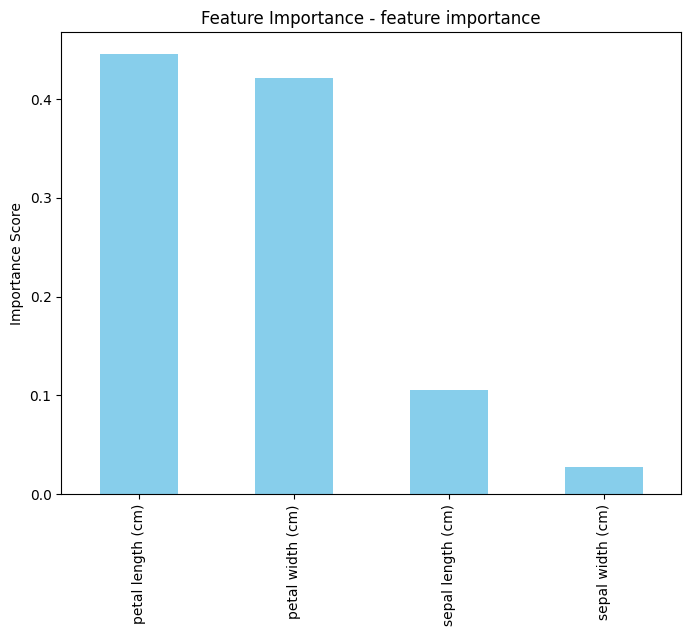

In [10]:
# plotting the feature importance

import matplotlib.pyplot as plt
plt.figure(figsize =(8,6))
importances.plot(kind='bar', color='skyblue')
plt.title('Feature Importance - feature importance')
plt.ylabel('Importance Score')
plt.show()

In [ ]:
# tuning - how accuracy changes as we change the number of rows
test_score = []
n_trees_range =[1, 5, 10, 25, 50, 100, 200, 500]

for n in  n_trees_range:
    rf = RandomForestClassifier(n_estimators = n, random_state = 42)
    rf.fit(X_train, y_train)
    test_score.append(accuracy_score(y_test, rf.predict(X_test)))

print(test_score)

[1.0, 0.9666666666666667, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


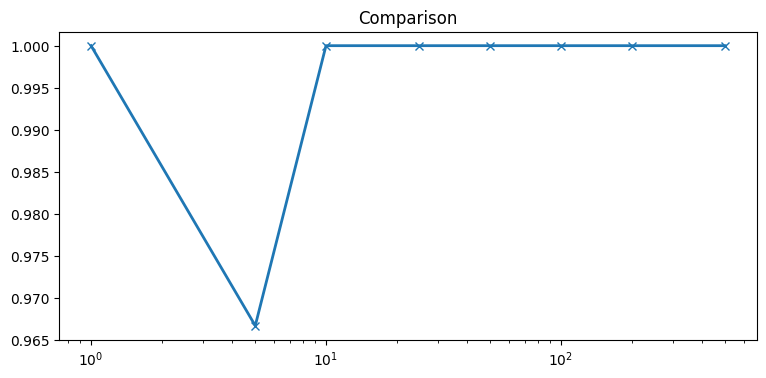

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,4))
plt.plot(n_trees_range , test_score, marker = 'x', linewidth=2)
plt.xscale('log')
plt.title ('Comparison')
plt.show()

# Gradient boosting, XGBoost and Bias-Variance
## Boosting - learning from mistakes
-> Random forest trains trees in parallel (Independently of each other).

-> Boosting trains trees  sequentially - each new tree focuses on the mistakes the previous
tree made.

## Gradient boosting vs XGBoost
Speed -> 

In [14]:
# loading the iris dataset
from sklearn.datasets import load_iris
iris = load_iris()


In [15]:
# spliting
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(iris.data,iris.target, test_size=0.2,random_state=42)

In [27]:
# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators = 100,
    learning_rate = 0.1, #Learning rate shrinks the contribution of each tree by learning_rate
    max_depth = 3,
    random_state = 42
)
gb.fit(X_train, y_train)
print(f'Gradient boosting accuracy: {accuracy_score(y_test, gb.predict(X_test)):.2%}')

Gradient boosting accuracy: 100.00%


In [29]:
# create model XGBClassifier . -> extreme gradient boosting classifier
from  xgboost import XGBClassifier    

xgb = XGBClassifier(
    n_estimator = 100,
    learning_rate = 0.1,
    max_depth = 3,
    eval_metric = 'mlogloss',
    verbosity = 0
)

# Train our model

xgb.fit(X_train, y_train)
print(f'XGBoost accuracy score: {accuracy_score(y_test, xgb.predict(X_test)):.2%}')

XGBoost accuracy score: 100.00%


# The bias-variance tradeoff
-> (Balancing) you don't want your model to be so generalized or too localized
This explains the fundamental tension between a model that is too simple and one that is too complex.


|High Bias (Underfitting) | High Variance (Overfitting) |
|---| ---|
|Model is too simple (misses real patterns) | Model is too complex (memorizes training data)
|Both train and test errors are high | Very low train error, high test error
|FIX: More complex model, more features, less regularization | FIX: more data, regularization, simpler model, ensembles.


GOAL: Find the sweet spot - Complex enough to capture real patterns but simple enough to 
generlized to new data.

- Ensembles methods (especially random forest and XGBoost) are powerful partly because they 
reduce variance without increasing much bias